In [17]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

读取数据

In [18]:
df = pd.read_csv('spambase.csv')
print(df.shape) 

(4601, 58)


特征与标签

In [19]:
X = df.iloc[:, :-1]             # 前57列特征
y = df.iloc[:, -1]              # spam：0=非垃圾, 1=垃圾

划分测试集

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

标准化

In [21]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

训练模型

In [22]:
model = SVC(kernel='linear', class_weight='balanced', random_state=42)
model.fit(X_train, y_train)

SVC(class_weight='balanced', kernel='linear', random_state=42)

预测并评估

In [23]:
y_pred = model.predict(X_test)
print('准确率:', accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=['非垃圾', '垃圾']))

准确率: 0.9275887038377987
              precision    recall  f1-score   support

         非垃圾       0.94      0.94      0.94       837
          垃圾       0.91      0.91      0.91       544

    accuracy                           0.93      1381
   macro avg       0.92      0.92      0.92      1381
weighted avg       0.93      0.93      0.93      1381



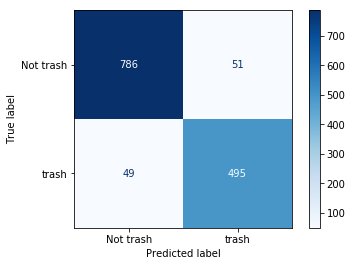

In [24]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=['Not trash', 'trash'], cmap='Blues')
plt.show()